In [1]:
# 1. Installation des dépendances SOTA
!pip install timm scikit-learn opencv-python-headless tqdm matplotlib seaborn

import os
import torch
import torch.nn.functional as F
import torchvision.transforms as T
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights
from torchvision.models.feature_extraction import create_feature_extractor
import cv2
import numpy as np
from glob import glob
from tqdm import tqdm
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from IPython.display import display, clear_output

# 2. Montage du Google Drive
drive.mount('/content/drive')

# 3. Configuration des chemins
DATASET_PATH = "/content/drive/MyDrive/AUTOMATED DEFECT/dataset"
OUTPUT_PATH = "/content/memory_bank"

# Création du dossier de sortie local
os.makedirs(OUTPUT_PATH, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Système opérationnel. Exécution sur : {device}")
print(f"📂 Les modèles seront générés dans : {OUTPUT_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🚀 Système opérationnel. Exécution sur : cuda
📂 Les modèles seront générés dans : /content/memory_bank


In [ ]:
# Chargement du modèle expert
base_model = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1).to(device)
base_model.eval()

# Extraction des couches spatiales (Layer 2 & 3)
return_nodes = {'layer2': 'layer2', 'layer3': 'layer3'}
feature_extractor = create_feature_extractor(base_model, return_nodes=return_nodes)

# Pipeline de transformation standard industriel
transform = T.Compose([
    T.ToPILImage(),
    T.Resize((256, 256)),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def extract_features(tensor_img):
    with torch.no_grad():
        features = feature_extractor(tensor_img)
    f2, f3 = features['layer2'], features['layer3']
    f3_up = F.interpolate(f3, size=f2.shape[2:], mode='bilinear', align_corners=False)
    concat = torch.cat([f2, f3_up], dim=1)

    return concat.squeeze(0).view(concat.size(1), -1).t()

In [ ]:
def process_production_line(category):
    print(f"\n{'-'*50}\n🏗️ ANALYSE LIGNE : {category.upper()}\n{'-'*50}")

    # --- PHASE 1 : APPRENTISSAGE (Memory Bank sur GPU) ---
    train_paths = glob(os.path.join(DATASET_PATH, category, "train", "good", "*.png"))
    patch_bank = []

    for img_path in tqdm(train_paths, desc=f"Extraction {category}", leave=True):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        tensor = transform(img).unsqueeze(0).to(device)
        patches = extract_features(tensor) 

        # Mémorisation de 25% des patches pour la précision
        idx = torch.randperm(patches.size(0), device=device)[:int(patches.size(0) * 0.25)]
        patch_bank.append(patches[idx])

    # Création du tenseur géant sur la VRAM du GPU T4
    memory_bank = torch.cat(patch_bank, dim=0)

    # Sauvegarde locale du fichier .pt
    model_path = os.path.join(OUTPUT_PATH, f"{category}_model.pt")
    torch.save(memory_bank.cpu(), model_path)

    # --- PHASE 2 : ÉVALUATION FULL GPU (Temps Réel) ---
    test_dir = os.path.join(DATASET_PATH, category, "test")
    test_data = []
    for subdir in os.listdir(test_dir):
        if os.path.isdir(os.path.join(test_dir, subdir)):
            label = 0 if subdir == "good" else 1
            for p in glob(os.path.join(test_dir, subdir, "*.png")):
                test_data.append((p, label))

    y_true, y_scores = [], []
    for img_path, label in tqdm(test_data, desc=f"Évaluation {category}", leave=True):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        tensor = transform(img).unsqueeze(0).to(device)
        test_patches = extract_features(tensor) # [784, 1536] sur GPU

        # Calcul des distances Euclidiennes entre les 784 patches test et les ~40,000 patches en mémoire
        # Fait en un seul appel matriciel ultra-optimisé sur GPU
        distances = torch.cdist(test_patches, memory_bank) # Shape: [784, N_bank]
        min_distances, _ = torch.min(distances, dim=1)     # Trouve le patch normal le plus proche
        image_score = min_distances.max().item()           # Récupère la pire anomalie

        y_true.append(label)
        y_scores.append(image_score)

    auroc = roc_auc_score(y_true, y_scores)

    # --- PHASE 3 : RÉSULTATS VISUELS ---
    clear_output(wait=True)
    print(f"🏆 SCORE FINAL {category.upper()} : AUROC = {auroc:.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Courbe ROC
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    axes[0].plot(fpr, tpr, color='blue', lw=2, label=f'AUROC = {auroc:.4f}')
    axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--')
    axes[0].set_title(f'ROC Curve - {category}')
    axes[0].legend()

    # Matrice de Confusion
    thresh = np.percentile(np.array(y_scores)[np.array(y_true)==0], 95)
    y_pred = (np.array(y_scores) > thresh).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[1],
                xticklabels=['Sain', 'Défaut'], yticklabels=['Sain', 'Défaut'])
    axes[1].set_title(f'Confusion Matrix - {category}')

    plt.show()
    return auroc

🏆 SCORE FINAL ZIPPER : AUROC = 0.9183


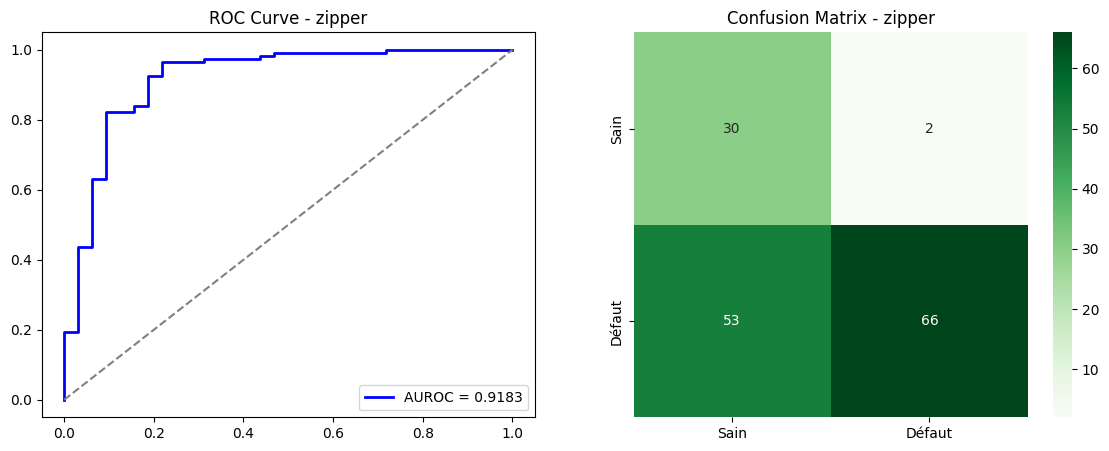


📊 RÉCAPITULATIF DES PERFORMANCES
- bottle          : 0.9968
- cable           : 0.9365
- capsule         : 0.9178
- carpet          : 0.9920
- grid            : 0.7385
- hazelnut        : 0.9986
- leather         : 0.9997
- metal_nut       : 0.9765
- pill            : 0.8704
- screw           : 0.9129
- tile            : 0.9242
- toothbrush      : 0.9917
- transistor      : 0.8888
- wood            : 0.9886
- zipper          : 0.9183

✅ Terminé ! Tes 15 modèles sont dans le dossier : /content/memory_bank


In [8]:
all_categories = sorted([d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d))])
final_results = {}

for cat in all_categories:
    final_results[cat] = process_production_line(cat)

print("\n" + "="*50)
print("📊 RÉCAPITULATIF DES PERFORMANCES")
print("="*50)
for cat, score in final_results.items():
    print(f"- {cat.ljust(15)} : {score:.4f}")

print(f"\n✅ Terminé ! Tes 15 modèles sont dans le dossier : {OUTPUT_PATH}")

## Affichage des courbes ROC

📊 Génération de la planche de résultats finale...


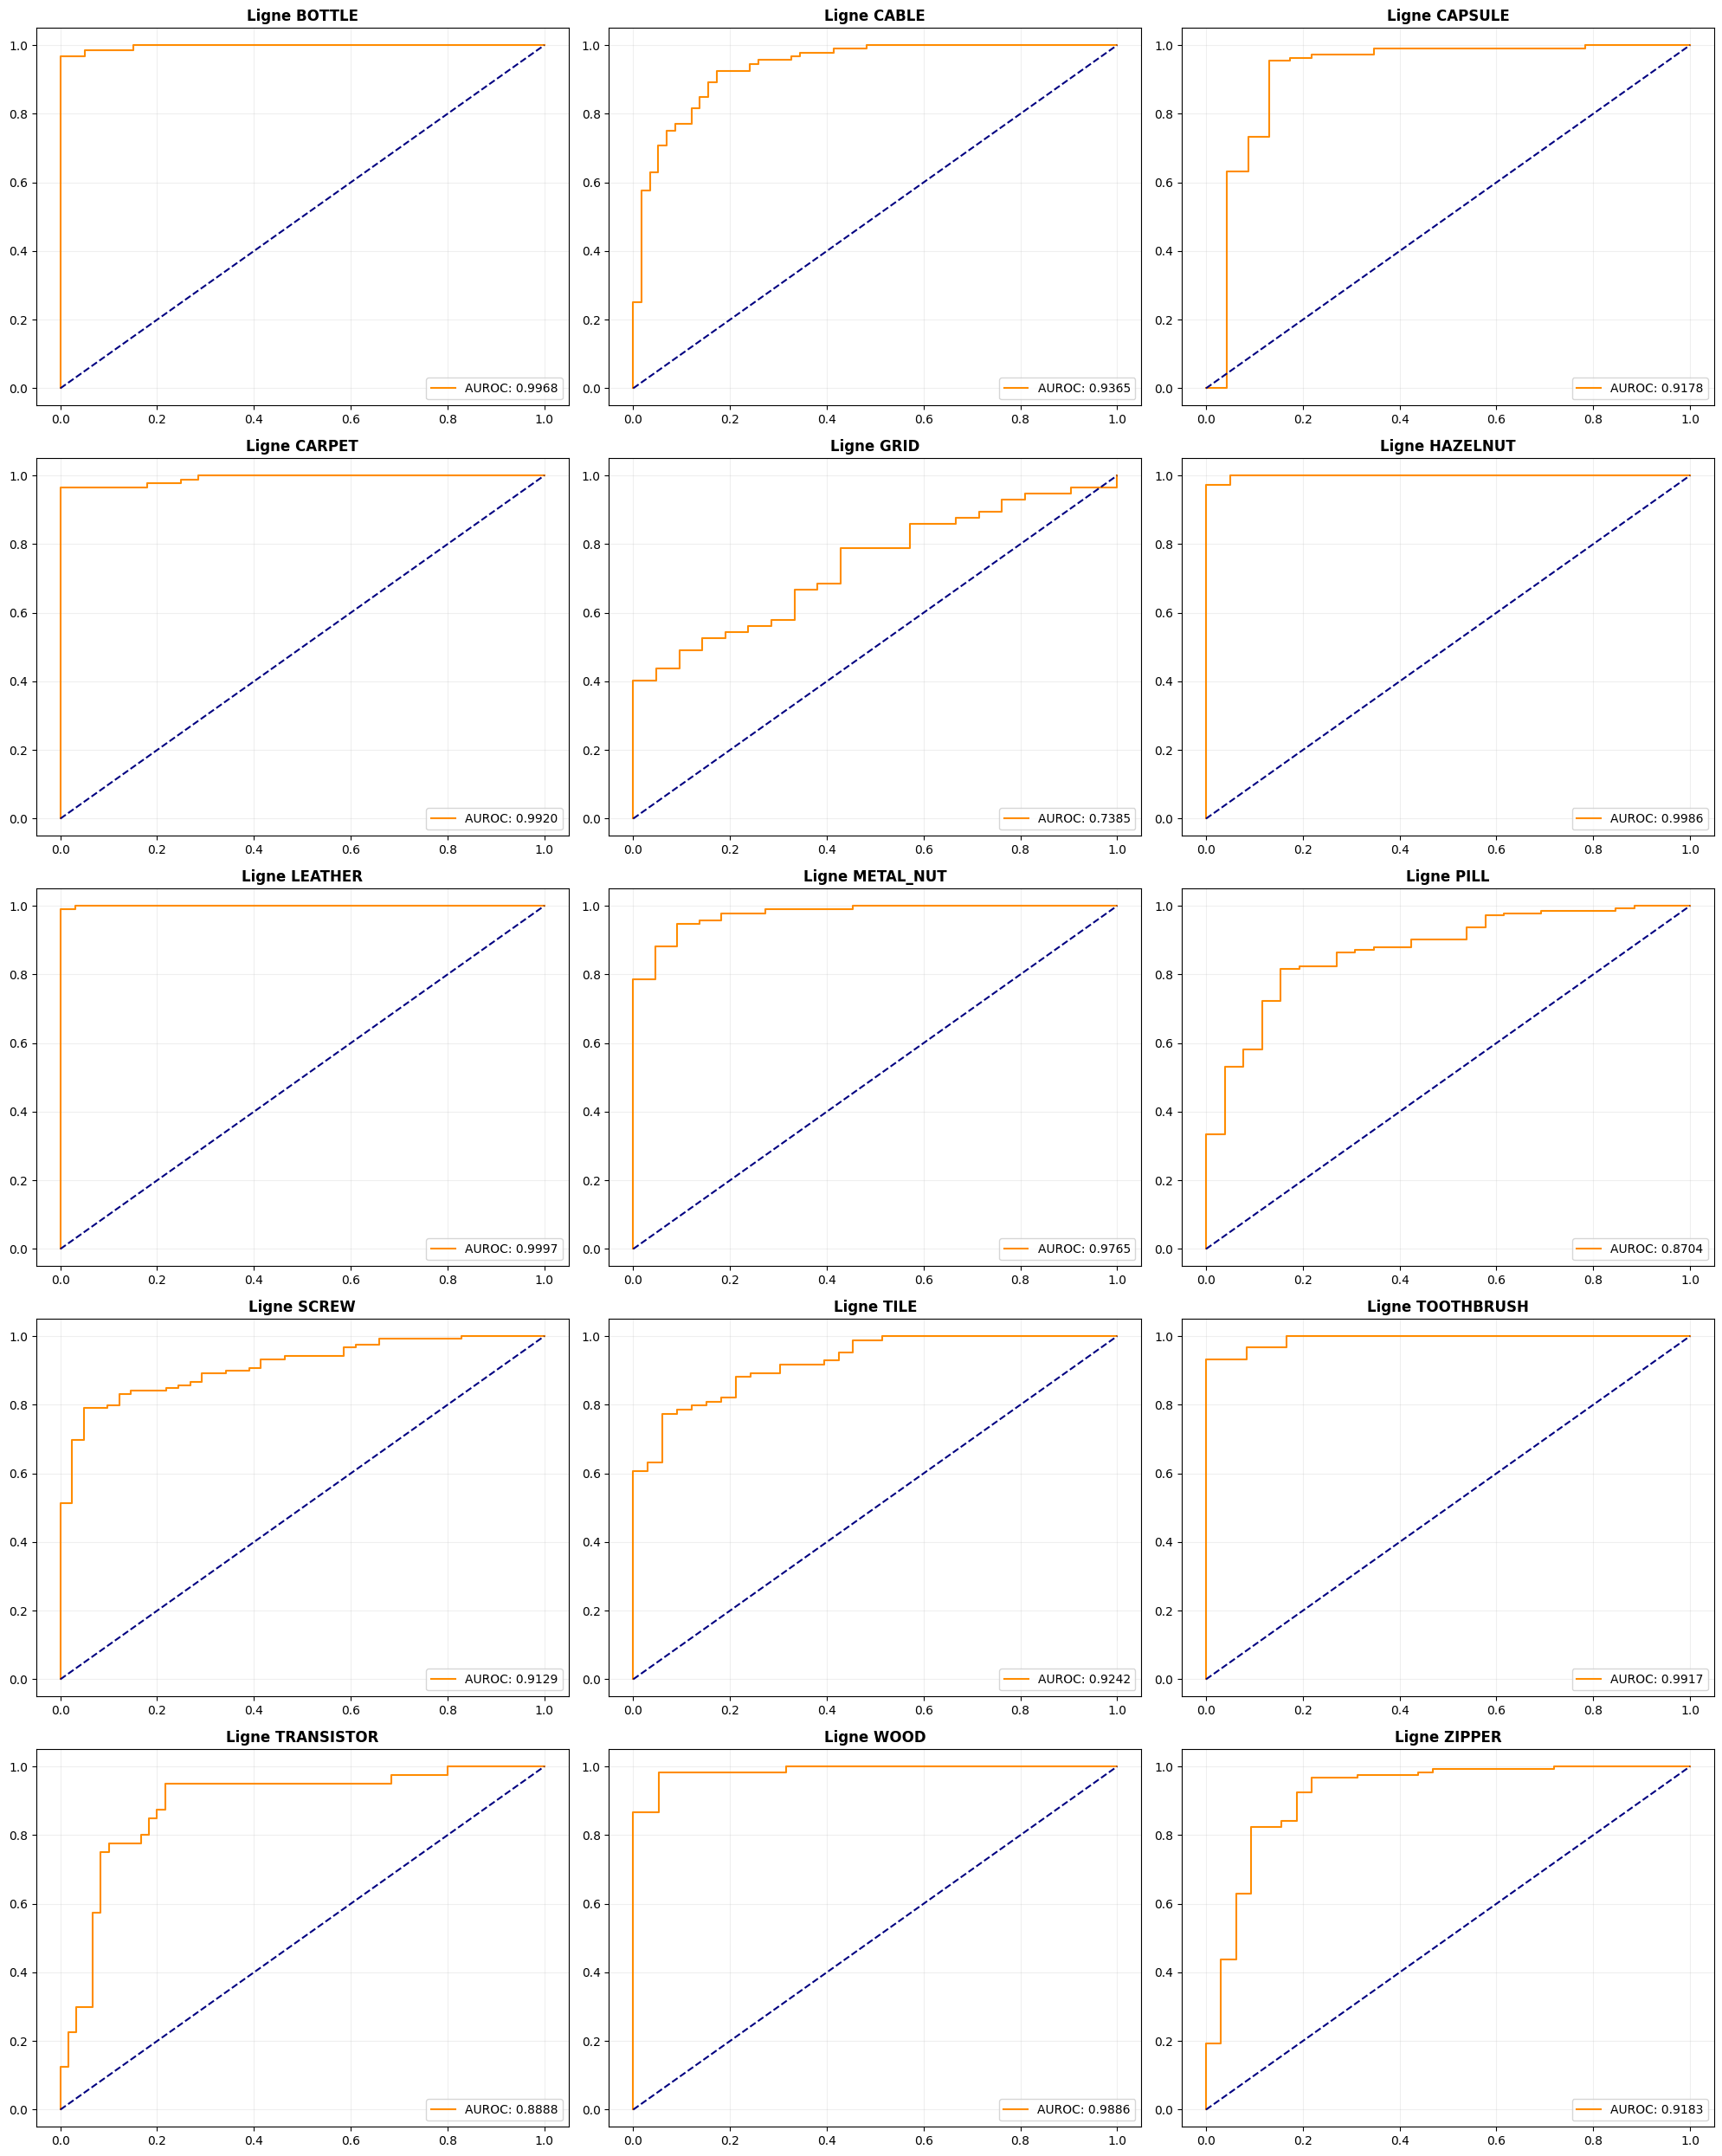

In [9]:
import math

def generate_final_dashboard(results_dict):
    num_cats = len(results_dict)
    cols = 3
    rows = math.ceil(num_cats / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 5))
    axes = axes.flatten()

    print("📊 Génération de la planche de résultats finale...")

    for i, (category, score) in enumerate(results_dict.items()):
        # On recalcule rapidement les scores pour le graphique (Full GPU speed)
        test_dir = os.path.join(DATASET_PATH, category, "test")
        test_data = []
        for subdir in os.listdir(test_dir):
            if os.path.isdir(os.path.join(test_dir, subdir)):
                label = 0 if subdir == "good" else 1
                for p in glob(os.path.join(test_dir, subdir, "*.png")):
                    test_data.append((p, label))

        y_true, y_scores = [], []
        # On charge le modèle déjà sauvegardé
        bank = torch.load(f"{OUTPUT_PATH}/{category}_model.pt").to(device)

        for img_path, label in test_data:
            img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
            tensor = transform(img).unsqueeze(0).to(device)
            patches = extract_features(tensor)
            dist = torch.cdist(patches, bank)
            y_true.append(label)
            y_scores.append(dist.min(dim=1)[0].max().item())

        # Affichage simplifié sur la grille
        fpr, tpr, _ = roc_curve(y_true, y_scores)
        axes[i].plot(fpr, tpr, color='darkorange', label=f'AUROC: {score:.4f}')
        axes[i].plot([0, 1], [0, 1], color='navy', linestyle='--')
        axes[i].set_title(f'Ligne {category.upper()}', fontweight='bold')
        axes[i].legend(loc="lower right")
        axes[i].grid(alpha=0.2)

    # Nettoyage des axes vides
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig("full_dashboard_results.png", dpi=300)
    plt.show()

# Lancement du dashboard
generate_final_dashboard(final_results)